# Can bounded gains denoise an independent path signal?
We first isolate the reconstruction signal readout at rank 8. We then exercise it inside an untrained ESDM. The hard bound applies to modal gains, not to the wave amplitude, posterior sample, reconstructed feature or loss.

From the repository root: `uv run --no-sync python notebooks/run.py`. The paired per-case differences, gains, permutation and split hashes are in `docs/paper/v2-results/experiment.json`.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display
from esdm.experiments.v2_readout import path_data, decoding_experiment, model_boundary, protocol
torch.set_num_threads(1)
data = path_data()
p = protocol(data)
print(f"CPU seed={p['seed']} | q={p['readout_rank']}/{p['features']} | {p['n_train']} train / {p['n_test']} held out | clean test SHA-256: {p['test_clean_sha256'][:16]}")

CPU seed=3407 | q=8/32 | 512 train / 512 held out | clean test SHA-256: dd69ee8ef573069c


### What differs between arms?
Each input is a clean analytic path signal (modal variance $1/(1+(k/4)^2)$) plus independent Gaussian noise of SD 0.15 in every feature. Targets are the original clean signals. The generator never uses the prime grid. Every arm uses the same train/test cases, noise and leading eight DCT-II modes. The other 24 directions have gain one; there is no clock noise or trainable wave block in this comparison.

- **Identity:** keep all gains at one.
- **Smooth envelope:** identical radius per mode to the prime arm, initialise logits to zero (unit gains), then fit.
- **Prime:** initialise `BoundedSpectralReadout` with the inclusive prime count divided by the unoffset logarithmic integral, then fit the same logits.
- **Shuffled:** permute the prime **normalised** residuals across mode indices, leaving the histogram and per-mode radii unchanged. This is a control for prime ordering, not an independently generated set of residual values.
- **Free:** unconstrained diagonal gains, initialised at one.

All four trainable arms get 100 full-batch Adam updates (LR 0.05) on mean squared feature error, with no tuning on held-out data. Equal update budgets need not imply equal convergence across parameterisations.

In [2]:
decoding = decoding_experiment(data)
print('Arm        Initial MSE    Trained MSE    Final gain interval')
for name, arm in decoding['arms'].items():
    gains = arm['trained']['gains']
    print(f"{name:<10} {arm['initial']['mse']:.9f}    {arm['trained']['mse']:.9f}    [{min(gains):.5f}, {max(gains):.5f}]")
for phase in ('initial','trained'):
    print(f'\n{phase}: prime minus comparison (paired MSE differences, 95% case bootstrap CI)')
    for name, d in decoding['contrasts'][phase].items():
        if name.startswith('prime_minus_'):
            lo, hi = d['ci95']; print(f"  {name:>20}: {d['mean']:+.3e} [{lo:+.3e}, {hi:+.3e}]")

Arm        Initial MSE    Trained MSE    Final gain interval
identity   0.022514806    0.022514806    [1.00000, 1.00000]
smooth     0.022514806    0.022374183    [0.97089, 0.98329]
prime      0.022420285    0.022373389    [0.97055, 0.98312]
shuffled   0.022414795    0.022373259    [0.97040, 0.98306]
free       0.022514806    0.022319945    [0.94371, 0.97983]

initial: prime minus comparison (paired MSE differences, 95% case bootstrap CI)
  prime_minus_identity: -9.452e-05 [-1.234e-04, -6.758e-05]
    prime_minus_smooth: -9.452e-05 [-1.234e-04, -6.758e-05]
  prime_minus_shuffled: +5.490e-06 [-3.440e-06, +1.422e-05]
      prime_minus_free: -9.452e-05 [-1.234e-04, -6.758e-05]

trained: prime minus comparison (paired MSE differences, 95% case bootstrap CI)
  prime_minus_identity: -1.414e-04 [-1.835e-04, -1.012e-04]
    prime_minus_smooth: -7.940e-07 [-1.558e-06, -4.098e-08]
  prime_minus_shuffled: +1.307e-07 [-7.883e-08, +3.277e-07]
      prime_minus_free: +5.344e-05 [+2.347e-05, +8.446e-0

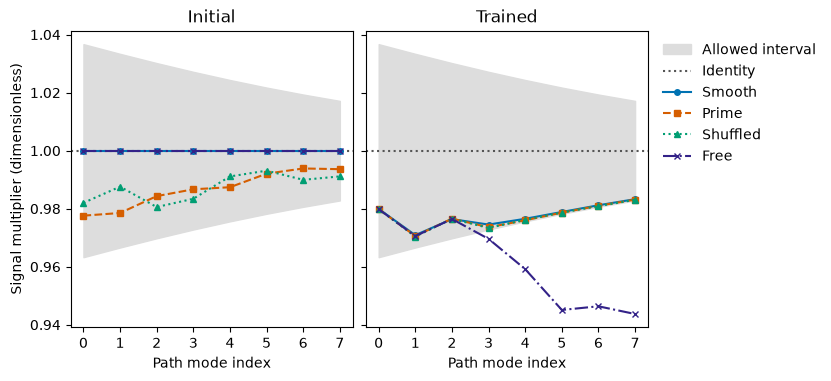

In [3]:
r = np.array(decoding['radius']); k = np.arange(len(r))
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.7), layout='constrained', sharey=True)
for ax, stage in zip(axes, ('initial','trained')):
    ax.fill_between(k, 1-r, 1+r, color='#DDDDDD', label='Allowed interval')
    ax.axhline(1, color='#555555', linestyle=':', label='Identity')
    for name, style, colour in [('smooth','o-','#0072B2'),('prime','s--','#D55E00'),('shuffled','^:','#009E73'),('free','x-.','#332288')]:
        ax.plot(k, decoding['arms'][name][stage]['gains'], style, color=colour, label=name.capitalize(), markersize=4)
    ax.set(title=stage.capitalize(), xlabel='Path mode index', xticks=k)
axes[0].set_ylabel('Signal multiplier (dimensionless)')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.01,1), frameon=False)
plt.show()

### Model boundary and amplitude check
The input below excites one retained eigenmode at amplitudes 1, 10 and 1000. We measure its output by projecting back onto that same eigenvector. The two complete ESDM forwards use distinct clean batches so the second pass can advance the clock. Both compare the model’s output to the explicit zero-noise clock-scaled readout of the stored raw wave state. The first pass is a zero-time check, not a generation test.

In [4]:
boundary = model_boundary(data)
print('Single-mode input -> measured modal output (first gain %.7f)' % boundary['first_gain'])
for a, b in zip(boundary['modal_input'], boundary['modal_output']): print(f'{a:7g} -> {b:10.5f}')
print(f"\nActual ESDM.encode: mu {boundary['mu_shape']}, logvar {boundary['logvar_shape']}, sample norms {np.round(boundary['z_norm_range'],4)}")
for i, run in enumerate(boundary['forward_passes'], 1):
    print(f"Forward {i}: tau={run['tau']:.6g}, alpha_bar={run['alpha_bar']:.8g}, raw norms={np.round(run['raw_wave_norm_range'],4)}, MSE={run['feature_mse']:.6g}, ELBO loss={run['loss']:.5g}, max readout discrepancy={run['max_abs_explicit_readout_error']:.3g}")

Single-mode input -> measured modal output (first gain 0.9776010)
      1 ->    0.97760
     10 ->    9.77601
   1000 ->  977.60095

Actual ESDM.encode: mu [8, 8], logvar [8, 8], sample norms [1.5442 4.3593]
Forward 1: tau=0, alpha_bar=1, raw norms=[1.8149 2.7153], MSE=2.49169e-05, ELBO loss=16.349, max readout discrepancy=0
Forward 2: tau=3.23225, alpha_bar=0.99598312, raw norms=[2.1361 3.3668], MSE=5.30782e-05, ELBO loss=13.165, max readout discrepancy=0


All trained arms reduced held-out error relative to identity. The prime start improved on zero initialisation before fitting; the matched shuffle did too. After fitting, the prime arm beat the zero-start bounded arm by less than one millionth of a squared feature unit. Prime ordering showed no resolved advantage over shuffling: their paired interval includes zero. Free gains had the lowest error and left the allowed interval on higher retained modes.

The intervals concern held-out cases on one split and one fit; they do not include uncertainty across training sets, graphs, seeds or tasks. The shuffled arm tests assignment of a fixed residual histogram to modes. Neither a finite gain bound nor a small denoising difference would establish an advantage for prime initialisation on real data.

In [5]:
display({'application/json': {'decoding': decoding, 'model_boundary': boundary}, 'text/plain': 'Machine-readable decoding and model-boundary results.'}, raw=True)

Machine-readable decoding and model-boundary results.